








































































































<img src="mlns.png" style="width: 200%; height: auto;">

# Solución MicroProyecto 2

**Alcanzando los objetivos de desarrollo sostenible. Un aporte desde el machine learning.**

La Organización de las Naciones Unidas (ONU) adopta, el 25 de septiembre del año 2015, la Agenda 2030 para el desarrollo sostenible, cuyo fin es reducir la pobreza, garantizar acceso a la salud y educación, buscar igualdad de género y oportunidades y disminuir el impacto ambiental, entre otros propósitos. A tal efecto, define 17 objetivos de desarrollo sostenible (ODS) y 169 metas (derivadas de los diferentes ODS). Dentro del trabajo en conjunto de diferentes entes para alcanzar el cumplimiento de los objetivos de desarrollo sostenible definidos en la Agenda 2030, muchas entidades tienen como función el seguimiento y la evaluación de las políticas públicas y su impacto a nivel social. Este es el caso del Fondo de Población de las Naciones Unidas (UNFPA, por sus siglas en inglés), que, junto con instituciones públicas y haciendo uso de diferentes herramientas de participación ciudadana, busca identificar problemas y evaluar soluciones actuales, relacionando la información con los diferentes ODS. 

Uno de los procesos que requiere de un mayor esfuerzo es la interpretación y análisis de la información textual procedente de diferentes fuentes implicadas en la planeación participativa para el desarrollo a nivel territorial, ya que es una tarea que consume gran cantidad recursos y para la cual se requiere de expertos que relacionen los textos con los ODS. Este conocimiento facilitaría la toma de decisiones con base en la opinión de la población y permitiría encaminar las políticas públicas de manera más informada para el cumplimiento de la Agenda 2030.

El objetivo del proyecto es desarrollar una solución, basada en técnicas de procesamiento del lenguaje natural y machine learning, que permita clasificar automáticamente un texto según los 17 ODS, ofreciendo una forma de presentación de resultados a través de una herramienta de fácil comprensión para el usuario final.

**A. Objetivo.**

Desarrollar una solución, basada en técnicas de procesamiento de lenguaje natural y machine learning, que facilite la interpretación y análisis de información textual para la identificación de relaciones semánticas con los Objetivos de Desarrollo Sostenibles. 

**B. Conjunto de datos.** 

El conjunto de datos forma parte del proyecto “OSDG Community Dataset” (
OSDG-CD
), en su versión 2023, que contiene un total de 40.067 textos, de los cuales 3000 provienen de fuentes relacionadas con las Naciones Unidas. También contiene documentos públicos, resúmenes de artículos y reportes. La plataforma reúne investigadores, expertos en la materia y defensores de los ODS de todo el mundo para crear una fuente amplia y precisa de información textual sobre los ODS. Los voluntarios de la comunidad utilizan la plataforma para participar en ejercicios de etiquetado en los que validan la relevancia de cada texto para los ODS basándose en sus conocimientos previos. 

Los textos que serán utilizados en este proyecto fueron traducidos al español utilizando herramientas como 
Deepl
 . También se realizó una aumentación de textos a través del API de 
ChatGPT
. Los puedes descargar a partir de:

**C. Actividades para realizar.**

1. Preparación de los textos utilizando el esquema de bolsa de palabras (BOW)l con una pesado TF-IDF. Para este paso construir un pipeline que integre las transformaciones que se consideren adecuadas.

2. A partir de la matriz TF-IDF construida en el paso anterior, aplica el algoritmo SVD truncado (TruncatedSVD de scikit-learn) para obtener un modelo de tópicos mediante análisis semántico latente (LSA). Explora un número reducido de componentes (por ejemplo, entre 10 y 20) y, para al menos 5 de ellas, identifica y muestra las palabras con mayor peso (loadings), a modo de "tópicos". Interpreta cualitativamente si estos tópicos guardan relación con algunos de los 17 ODS trabajados en el proyecto.

3. Desarrollo de un modelo de clasificación que permita relacionar un texto con un ODS. Para manejar la complejidad del espacio de entrada, puedes reutilizar la misma descomposición SVD obtenida en la actividad anterior (LSA), o aplicar otro algoritmo de reducción de la dimensionalidad que consideres pertinente

4. Evaluación del modelo de clasificación con textos que no hayan sido utilizados para el aprendizaje.

**D. Consideraciones.**

El algoritmo de clasificación a utilizar, así como la técnica de reducción de la dimensionalidad, queda a consideración de cada grupo, pero es importante justificar la elección.

**E. Entregable.**

Notebook (*.ipynb y *.html) del método desarrollado. El Notebook debe estar documentado con las justificaciones de las decisiones tomadas en cada paso. Además, deben ser visibles las ejecuciones de cada celda. Para evidenciar el desempeño del método construido el notebook debe mostrar las clasificaciones para al menos cuatro textos del conjunto test.

Esta entrega debe realizarse al final de la semana 7, en donde encontrarás un espacio para adjuntar los dos archivos.

### 1. Importación de librerías requeridas


Importamos las librerías que son necesarias para el desarrollo del microproyecto

In [1]:
# Importar librerías
import pandas as pd
import pandas.api.types as ptypes
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import unicodedata

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem import SnowballStemmer
from wordcloud import WordCloud
from nltk.stem import WordNetLemmatizer

from sklearn.decomposition import TruncatedSVD

import joblib

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


### 2. Carga de datos

Realizaremos la carga de datos usando la función de Pandas `read_csv()`, especificando la ruta y el separador del archivo.

In [2]:
# Cargar la base
path = r"C:\Users\Usuario\Desktop\Maestría IA\6. Machine Learning No Supervisado\Datos_textosODS.xlsx"
columns = ["textos", "ODS"]
data = pd.read_excel(path, names=columns)
data.head()

,textos,ODS
0,"""Aprendizaje"" y ""educación"" se consideran sinó...",4
1,No dejar clara la naturaleza de estos riesgos ...,6
2,"Como resultado, un mayor y mejorado acceso al ...",13
3,Con el Congreso firmemente en control de la ju...,16
4,"Luego, dos secciones finales analizan las impl...",5


### 3.Pre-procesamiento Inicial
Iniciaremos con la revisión de los datos nulos y duplicados 

In [3]:
# Revisar valores duplicados
data.duplicated().sum()

np.int64(0)

In [4]:
# Revisar valores nulos
data.isna().sum()

textos    0
ODS       0
dtype: int64

No se identificaron valores duplicados o nulos en ambas columnas (textos y ODS). Al tratarse de un dataset ya curado, no fue necesario aplicar imputación ni eliminación de registros, por lo que se continúa directamente con la separación de las variables.

#### Separación de variable objetivo

Definiremos el conjunto de variables independientes y la variable objetivo:

In [5]:
# Definir la variable predictora
x=data.drop('ODS', axis=1)

# Definir la variable objetivo
y=data['ODS']

Además, usaremos la función `train_test_split()` para separar el conjunto de entrenamiento y el conjunto de pruebas. Usaremos el 80% como entrenamiento, y añadiremos el parámetro `stratify` para mantener las proporciones de la variable objetivo:

In [6]:
# Separar el conjunto el entrenamiento y prueba
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2,stratify=y, random_state=42)
x_train.head()

,textos
2376,"Por lo tanto, cabe esperar que el aumento de l..."
7665,"La tasa aumenta con el tiempo y, finalmente, u..."
3811,Su objetivo es mejorar las respuestas que reci...
1267,La mayor parte de la producción acuícola segui...
2770,"Según datos del Ministerio de Infancia, Educac..."


Se generan las funciones de limpiza a nivel de DataFrame

In [7]:
# Transforma a minúsculas 
def a_minusculas(texto):
    """Convierte a minúsculas todas las columnas de texto de un DataFrame"""
    for col in texto.columns:
        if ptypes.is_string_dtype(texto[col]) or ptypes.is_object_dtype(texto[col]):
            texto[col] = texto[col].str.lower()
    return texto

# Remover las tíldes
def remover_tildes(texto):
    """Eliminina tildes. Funciona tanto sobre un string como sobre un DataFrame"""
    # Crea un mapa de traducción que se utiliza para eliminar acentos/tíldes
    tabla_acentos = str.maketrans('áéíóúüÁÉÍÓÚÜ', 'aeiouuAEIOUU')
    if isinstance(texto, str):
        return texto.translate(tabla_acentos)
    else:
        # Para dataframes
        for col in texto.columns:
            if ptypes.is_string_dtype(texto[col]) or ptypes.is_object_dtype(texto[col]):
                texto[col] = texto[col].astype(str).str.translate(tabla_acentos)
        return texto

# Eliminar caracteres especiales (incluye signos puntuación)
"""Eliminia signos de puntuación y caracteres especiales"""
def eliminar_caracteres_especiales(texto):
    for col in texto.columns:
        if ptypes.is_string_dtype(texto[col]) or ptypes.is_object_dtype(texto[col]):
            # Busca cualquier carácter que NO este en el listado (negación) y lo reemplazo por espacio en blanco
            texto[col] = texto[col].str.replace(r'[^a-z0-9ñ\s]', ' ', regex=True)
            # Busca uno o más espacios en blanco seguidos y los reemplaza por un espacio en blanco 
            texto[col] = texto[col].str.strip().str.replace(r'\s+', ' ', regex=True)
    return texto

# Eliminar números (se deja aparte por control)
def eliminar_numeros(texto):
    """Elimina dígitos numéricos"""
    for col in texto.columns:
        if ptypes.is_string_dtype(texto[col]) or ptypes.is_object_dtype(texto[col]):
            texto[col] = texto[col].str.replace(r'\d', ' ', regex=True)
            texto[col] = texto[col].str.strip().str.replace(r'\s+', ' ', regex=True)
    return texto

In [8]:
# Definir el pipeline de preparación a nivel de DataFrame (limpieza básica)
pipeline_preparacion = Pipeline([
    ("a_minusculas", FunctionTransformer(a_minusculas)),
    ("remover_tildes", FunctionTransformer(remover_tildes)),
    ("eliminar_caracteres_especiales", FunctionTransformer(eliminar_caracteres_especiales)),
    ("eliminar_numeros", FunctionTransformer(eliminar_numeros))
])

In [9]:
# Generar el pipeline de preparación para los datos de entrenamiento
x_train_procesado = pipeline_preparacion.transform(x_train)
x_train_procesado

,textos
2376,por lo tanto cabe esperar que el aumento de lo...
7665,la tasa aumenta con el tiempo y finalmente un ...
3811,su objetivo es mejorar las respuestas que reci...
1267,la mayor parte de la produccion acuicola segui...
2770,segun datos del ministerio de infancia educaci...
...,...
5845,este estudio tiene como objetivo determinar la...
7625,y a pesar de la ausencia de una ley de compete...
2065,la tasa de recaudacion de tarifas cayo al y lo...
15,las guerras los conflictos armados y la ocupac...


Comprobamos el resultado con una fila que tenía tíldes, mayúsculas, carácteres especiales y números:

In [10]:
x_train_procesado.iloc[2376]

textos    estados unidos acordo un acuerdo politico glob...
Name: 510, dtype: object

Se confirma que el pipeline de limpieza funcionó correctamente: el texto original de la fila 2376 contenía tíldes, mayúsculas y signos de puntuación, y tras aplicar pipeline_preparación queda todo en minúscula, sin tildes, sin caracteres especiales y sin dígitos - listo para la etapa de tokenización y lematización.

### 4.Procesamiento

### Pipeline para el procesamiento de datos

Este pipeline tendra tanto el procesamiento de datos como el modelo que vamos a entrenar. Definiremos cada una de las etapas: 

#### Procesamiento de textos:

Vamos a reutilizar la función `text_preprocess()` para realizar todos los pasos del procesamiento de textos: tokenización, eliminación de palabras vacías y lematización:

Para este caso se decidio usar lematización porque identifica la forma base de una palabra teniendo en cuenta su contexto gramatical y significado, no se usa stemming porque al eliminar sufijos y prefijos puede generar palabras que no existen 


In [11]:
def text_preprocess(text):
    """Tokeniza, elimina stopwords en español y lematiza"""
    
    # Inicializa extractor que busca secuencia de caracteres alfanuméricos, ignorando automáticamente cualquier signo de puntuación
    tokenizer=RegexpTokenizer(r'\w+')
    # Inicializa reductor de palabras (reducción a su forma base)
    lemmatizer=WordNetLemmatizer()

    # Convierte el string en una lista de palabras individuales
    tokens=tokenizer.tokenize(text)
     # Remueve tíldes a las palabras que sobreviven el filtro de stopwords
    tokens=[remover_tildes(word) for word in tokens if word not in stopwords.words('spanish') ]
    # Pasa por el lematizador para convertir las palabras a su forma base
    tokens=[lemmatizer.lemmatize(word) for word in tokens]
    # Elimina todas las palabras que tienen menos de 3 caracteres
    tokens = [word for word in tokens if len(word) >= 3] 

    # Junta de nuevo todas las palabras limpias en una sola cadena de texto (string)
    return ' '.join(tokens)

In [12]:
x_train_texto = x_train_procesado["textos"].apply(text_preprocess)
x_train_texto.head()

2376    cabe esperar aumento niveles ingresos posterio...
7665    tasa aumenta tiempo finalmente numero suficien...
3811    objetivo mejorar respuestas reciben servicios ...
1267    mayor parte produccion acuicola seguira origen...
2770    segun datos ministerio infancia educacion igua...
Name: textos, dtype: object

Sobre el texto ya limpio, text_preprocess() aplica una segunda capa de procesamiento específica para el modelado: tokeniza texto, elimina palabras vacías (stopwords), en español, remueve tildes residuales en cada token, lematiza cada palabra a su forma base, y descarta tokens de menos de 3 caracteres. El resultado es un texto considerablemente más corto y compuesto solo por palabras con cargas semántica relevante para la clasificación.

In [13]:
# Vectorización TF-IDF
vectorizer=TfidfVectorizer()

In [14]:
# Vectorizamos x_traint_texto (ya con el texto preprocesado)
tfidf_matrix_train = vectorizer.fit_transform(x_train_texto)

Vamos a usar la clase `WordCloud()` para generar una imagen:

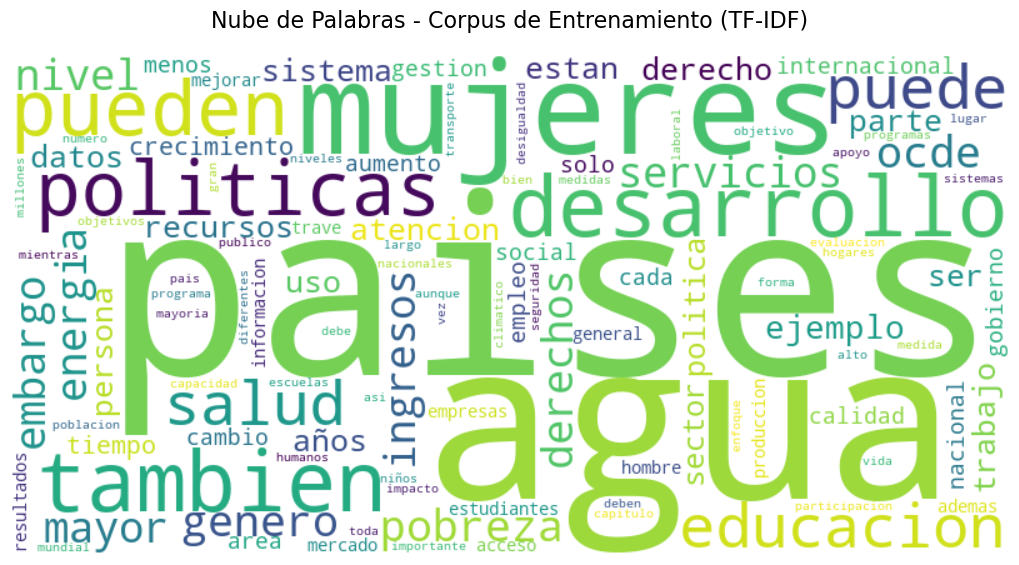

In [15]:
# Obtener los términos (feature names) del vectorizador TF-IDF
feature_names=vectorizer.get_feature_names_out()

# Obtener la matriz TF-IDF en formato array
tfidf_array=tfidf_matrix_train.toarray()

# Calcular la suma de TF-IDF por cada palabra (importancia total)
word_freq=tfidf_array.sum(axis=0)

# Crear un diccionario palabra:frecuencia
word_dict=dict(zip(feature_names, word_freq))

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
    max_words=110,
    min_font_size=10
).generate_from_frequencies(word_dict)

# Mostrar la nube de palabras
plt.figure(figsize=(10, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de Palabras - Corpus de Entrenamiento (TF-IDF)', fontsize=16, pad=20)
plt.tight_layout(pad=0)
plt.show()

La nube de palabras muestra los términos con mayor peso TF-IDF acumulado en el corpus de entrenamiento. Se observa que términos como paises, agua, mujeres, desarrollo, salud, educación, pobreza, entre otras, dominan visualmente, lo que sugiere que el corpus está fuertemente orientado hacia temas de fin de pobreza, educación de calidad, igualdad de genero, agua limpia y seneamiento, energía asequible y no contaminante, coherente con la naturaleza multi-ODS del datase. 

# 5. Reducción de dimensionalidad

Utilizaremos la clase `TruncatedSVD()` para aplicar la descomposición en valores singulares sin centrar los datos. Además, seguiremos lo que nos sugiere el microproyecto y utilizaremos el número recomendado de componentes  (`n_components=20`):

In [16]:
# PASO 2: Entrenar LSA en los datos de ENTRENAMIENTO
# Configuración y entrenamiento de TruncatedSVD
# Número de componentes 
componentes_a_probar = list(range(1, 21))

# Entrenar el modelo con el número de componentes definidos
for n in componentes_a_probar:
    svd = TruncatedSVD(n_components=n, n_iter=100, random_state=42)
    x_train_lsa=svd.fit_transform(tfidf_matrix_train)

    # Varianza encontrada según número de componentes
    varianza_total = svd.explained_variance_ratio_.sum()
    print(f"Con {n} componentes, se retiene el {varianza_total:.2%} de la información (varianza).")

Con 1 componentes, se retiene el 0.16% de la información (varianza).
Con 2 componentes, se retiene el 0.74% de la información (varianza).
Con 3 componentes, se retiene el 1.22% de la información (varianza).
Con 4 componentes, se retiene el 1.67% de la información (varianza).
Con 5 componentes, se retiene el 2.07% de la información (varianza).
Con 6 componentes, se retiene el 2.46% de la información (varianza).
Con 7 componentes, se retiene el 2.82% de la información (varianza).
Con 8 componentes, se retiene el 3.13% de la información (varianza).
Con 9 componentes, se retiene el 3.39% de la información (varianza).
Con 10 componentes, se retiene el 3.64% de la información (varianza).
Con 11 componentes, se retiene el 3.88% de la información (varianza).
Con 12 componentes, se retiene el 4.10% de la información (varianza).
Con 13 componentes, se retiene el 4.31% de la información (varianza).
Con 14 componentes, se retiene el 4.51% de la información (varianza).
Con 15 componentes, se retien

Con 20 componentes, el modelo LSA retiene apenas el 5.58% de la varianza total. Este porcentaje, aunque parece bajo, es esperado y normal en matrices TF-IDF de texto, a diferencia de datos numéricos densos, una matriz TF-IDF tiene miles de dimensiones (una por cada palabra del vocabulario) y la información real está distribuida de forma muy dispersa entre ellas, ningún componente individual concentra mucha varianza. Lo relevante no es maximizar el porcentaje retenido, sino que los 20 componentes logren capturar patrones semánticos útiles para separar las clases, lo cual se valida más adelante con el desempeño de los modelos de clasificación y con los tópicos interpretables mostrados a continuación.

In [17]:
# Función para mostrar las palabras con mayor peso de un tópico generado por modelo LSA/SVD

def mostrar_topico(componente_idx, feature_names, top_n=10):

    # Extraer la fila de la matriz del modelo
    pesos = svd.components_[componente_idx]
    # Ordenar y seleccionar las palabras
    indices_top = pesos.argsort()[::-1][:top_n]
    # Asociar índices con palabras reales
    palabras_top = [(feature_names[i], pesos[i]) for i in indices_top]
    
    return palabras_top

In [18]:
# Mostras las palabras de al menos 5 tópicos
feature_names = vectorizer.get_feature_names_out()

for i in range(5):
    palabras = mostrar_topico(i, feature_names, top_n=10)
    print(f"Tópico {i+1}:")
    for palabra, peso in palabras:
        print(f"  {palabra}: {peso:.3f}")
    print()

Tópico 1:
  mujeres: 0.173
  paises: 0.164
  agua: 0.158
  desarrollo: 0.128
  tambien: 0.120
  genero: 0.112
  politicas: 0.107
  educacion: 0.105
  salud: 0.101
  pueden: 0.101

Tópico 2:
  agua: 0.621
  energia: 0.132
  gestion: 0.087
  uso: 0.080
  recursos: 0.070
  residuales: 0.069
  subterraneas: 0.065
  suministro: 0.064
  riego: 0.052
  hidricos: 0.051

Tópico 3:
  derechos: 0.334
  agua: 0.288
  mujeres: 0.266
  derecho: 0.262
  humanos: 0.217
  genero: 0.197
  internacional: 0.151
  articulo: 0.114
  igualdad: 0.106
  hombre: 0.078

Tópico 4:
  agua: 0.476
  mujeres: 0.424
  genero: 0.196
  hombre: 0.182
  pobreza: 0.094
  ingresos: 0.083
  igualdad: 0.076
  laboral: 0.072
  empleo: 0.067
  trabajo: 0.061

Tópico 5:
  salud: 0.279
  educacion: 0.243
  atencion: 0.233
  agua: 0.199
  estudiantes: 0.196
  escuelas: 0.181
  mental: 0.138
  calidad: 0.129
  servicios: 0.119
  aprendizaje: 0.110



### Analisis de tópicos:

Tópico 1: Este tópico se relaciona con temas de educación de calidad (ODS 4), igualdad de género (ODS 5) y trabajo decente y crecimiento económico (ODS 8), evidenciado por palabras como mujeres, paises, agua, desarrolo.

Tópico 2: Este tópico aborda temas de agua limpia y saneamiento (ODS 6) y energía asequible y no contaminante (ODS 7), con un fuerte respaldo en palabras como agua, energia, gestion, energia, usos, recursos, residuales.

Tópico 3: Este tópico se relaciona claramente con paz, justicia e instituciones sólidas (0DS16), evidenciando por palabras como derechos, humanos, internacional, tribunal, ley, penal y trat(tratados), un conjunto de términos fines al ámbico jurídico e institucional.

Tópico 4: Este tópico combina varios ODS relacionados con desigualdad social: igualdad de género (ODS5), evidenciado por mujer, gener y hombr, agua limpia y saneamiento (ODS6), reflejado en el alto peso de agua, fin de la pobreza (ODS1), reflejado con pobrez, y trabajo decente y crecimiento económico (ODS8), con ingres, trabaj y emple.

Tópico 5: Este tópico integra servicios básicos esenciales: agua limpia y saneamiento (ODS6), con agu, hidric y residual, educación de calidad (ODS4), con educ, escuel y calid, y salud y bienestar (ODS3), con salud, atención y niñ, sugiriendo un tópico centrado en el acceso a servicios básicos para poblaciones vulnerables, particularmente niños.

### Desarrollo de un modelo de clasificación

Se entrena una SVM con kernel lineal, apropiado para datos de alta dimensionalidad como los generados por LSA, donde las clases suelen ser linealmente separables en el espacio reducido. Se usa class_weight='balanced' para compensar el desbalance entre categorías de ODS (por ejemplo, el ODS 4 tiene más del doble de registros que el ODS 9), ajustando automáticamente el peso de cada clase según su frecuencia inversa.

In [19]:
# Entrenar SVM
svm_model = SVC(kernel='linear', C=1.0, random_state=42, class_weight='balanced', probability=True)
svm_model.fit(x_train_lsa, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


##  Evaluación del modelo de clasificación con textos que no hayan sido utilizados para el aprendizaje.

In [20]:
# Procesamos x_test con el mismo pipeline de preparación 
x_test_procesado = pipeline_preparacion.transform(x_test)

# Aplicamos el mismo preprocesamiento de texto que en entrenamiento
x_test_texto = x_test_procesado["textos"].apply(text_preprocess)

# Vectorizamos x_test (ya con el texto preprocesado)
tfidf_matrix_test = vectorizer.transform(x_test_texto)

# Reducimos la dimensionalidad 
x_test_lsa = svd.transform(tfidf_matrix_test)

### Evaluación del modelo 

Empezaremos utilizando el método `predict()` para obtener la clasificación sobre el conjunto de prueba. 

In [21]:
y_pred=svm_model.predict(x_test_lsa)

In [22]:
#Métricas de desempeño:
accuracy= accuracy_score(y_test, y_pred)
precision=precision_score(y_test, y_pred, average='weighted')
recall=recall_score(y_test, y_pred, average='weighted')
f1=f1_score(y_test, y_pred, average='weighted')

print("=" * 60)
print("EVALUACIÓN DEL MODELO SVM CON KERNEL LINEAL")
print("=" * 60)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("=" * 60)

print("\nReporte detallado:")
print(classification_report(y_test, y_pred))

EVALUACIÓN DEL MODELO SVM CON KERNEL LINEAL
Accuracy: 0.7717
Precision: 0.8061
Recall: 0.7717
F1-Score: 0.7832

Reporte detallado:
              precision    recall  f1-score   support

           1       0.86      0.68      0.76       101
           2       0.70      0.70      0.70        74
           3       0.92      0.80      0.85       179
           4       0.95      0.90      0.92       205
           5       0.92      0.87      0.89       214
           6       0.91      0.84      0.88       139
           7       0.94      0.76      0.84       158
           8       0.55      0.54      0.55        89
           9       0.35      0.74      0.47        69
          10       0.61      0.66      0.63        70
          11       0.76      0.68      0.72       122
          12       0.50      0.58      0.54        62
          13       0.85      0.77      0.81        93
          14       0.42      0.60      0.50        75
          15       0.59      0.71      0.65        66
    

In [23]:
#Ahora con randomForest
RandomForest_model = RandomForestClassifier(n_estimators=100,max_depth=15,random_state=42,class_weight='balanced',n_jobs=-1)
RandomForest_model.fit(x_train_lsa, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [24]:
y_pred2=RandomForest_model.predict(x_test_lsa)

In [25]:
#Métricas de desempeño:
accuracy= accuracy_score(y_test, y_pred2)
precision=precision_score(y_test, y_pred2, average='weighted')
recall=recall_score(y_test, y_pred2, average='weighted')
f1=f1_score(y_test, y_pred2, average='weighted')

print("=" * 60)
print("EVALUACIÓN DEL MODELO RANDOMFOREST")
print("=" * 60)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("=" * 60)

print("\nReporte detallado:")
print(classification_report(y_test, y_pred2))

EVALUACIÓN DEL MODELO RANDOMFOREST
Accuracy: 0.7914
Precision: 0.7952
Recall: 0.7914
F1-Score: 0.7915

Reporte detallado:
              precision    recall  f1-score   support

           1       0.86      0.72      0.78       101
           2       0.65      0.74      0.69        74
           3       0.82      0.87      0.85       179
           4       0.94      0.94      0.94       205
           5       0.89      0.93      0.91       214
           6       0.89      0.86      0.88       139
           7       0.88      0.82      0.85       158
           8       0.58      0.47      0.52        89
           9       0.42      0.58      0.49        69
          10       0.68      0.69      0.68        70
          11       0.78      0.71      0.74       122
          12       0.65      0.52      0.58        62
          13       0.78      0.74      0.76        93
          14       0.54      0.57      0.56        75
          15       0.67      0.68      0.68        66
          16 

In [26]:
logreg = LogisticRegression(max_iter=500, random_state=42)
logreg.fit(x_train_lsa, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,500
,multi_class,'deprecated'


In [27]:
y_pred3=logreg.predict(x_test_lsa)

In [28]:
#Métricas de desempeño:
accuracy= accuracy_score(y_test, y_pred3)
precision=precision_score(y_test, y_pred3, average='weighted')
recall=recall_score(y_test, y_pred3, average='weighted')
f1=f1_score(y_test, y_pred3, average='weighted')

print("=" * 60)
print("EVALUACIÓN DEL MODELO REGRESIÓN LOGISTICA")
print("=" * 60)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("=" * 60)

print("\nReporte detallado:")
print(classification_report(y_test, y_pred3))

EVALUACIÓN DEL MODELO REGRESIÓN LOGISTICA
Accuracy: 0.7795
Precision: 0.7757
Recall: 0.7795
F1-Score: 0.7687

Reporte detallado:
              precision    recall  f1-score   support

           1       0.84      0.75      0.80       101
           2       0.69      0.69      0.69        74
           3       0.75      0.88      0.81       179
           4       0.84      0.97      0.90       205
           5       0.91      0.91      0.91       214
           6       0.91      0.88      0.90       139
           7       0.80      0.92      0.85       158
           8       0.53      0.44      0.48        89
           9       0.53      0.33      0.41        69
          10       0.75      0.57      0.65        70
          11       0.65      0.75      0.70       122
          12       0.84      0.34      0.48        62
          13       0.82      0.74      0.78        93
          14       0.68      0.51      0.58        75
          15       0.74      0.53      0.62        66
      

Random Forest tiene el mejor accuracy, recall y F1-score (el F1 pondera precisión y recall juntos, así que es el mejor resumen de desempeño general), y su precisión está muy cerca del máximo. La SVM tiene mejor precisión aislada pero peor en todo lo demás. Así que el modelo a desplegar es RandomForest_model.

In [29]:
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")
joblib.dump(svd, "svd_lsa.joblib")
joblib.dump(RandomForest_model, "model.joblib")

['model.joblib']

Para poder reutilizar este pipeline fuera del notebook en una aplicación "streamlit", se guardan con joblib los tres artefactos entrenados que son necesarios para reproducir el flujo completo sobre texto nuevo: el vectorizador TF-IDF ya ajustado al vocabulario de entrenamiento, el modelo LSA/SVD ya ajustado, y el modelo Random Forest, seleccionado como el de mejor desempeño general.